# How representations affect rule adherence in Vison-language model: A mech-interp walkthrough

A vision-language model reads a traffic-sign photo and applies a decision tree given in the prompt. Four ways of writing the same tree give the same accuracy, but one of them (lettered steps) lags behind the others on rule adherence 1 pp. This notebook follows the behaviour into the model's internals.

| | section | what it shows |
|:-:|---|---|
| 1️⃣ | **The task** | 22 traffic-sign classes, a 3-level tree, arbitrary labels |
| 2️⃣ | **Prompting strategies & results** | same accuracy; P1 (lettered steps) is 2–6× less rule-adherent |
| 3️⃣ | **What we extract** | residual stream at 5 answer slots, counterfactual forcing |
| 4️⃣ | **Content slot** | logit lens and forcing: P1's content gate is weak |
| 5️⃣ | **Probes** | a dead end: decodable is not the same as used |
| 6️⃣ | **Attention knockout** | shape jumps are a late retrieval from the other shape's rule lines |
| 7️⃣ | **Heads** | a few late heads (L27H18, L28H0, …) do that retrieval |
| 8️⃣ | **Failure detector** | one head flags shape jumps in every format |
| 9️⃣ | **Route knockout** | P2 anchors the list with its shape line; P1's step route goes unused |

All model outputs are precomputed (Qwen3-VL-8B-Instruct), so the notebook runs on a CPU in about a minute.

In [1]:
import json, re, warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore")
ROOT = Path.cwd(); H = ROOT / "data"; OUT = H / "runs/instruct-h3-interp"  # run from the repo root
import lib.answers as S   # class spec, answer tables, photos
import lib.knockout as KS  # knockout metrics
import lib.probes as D     # leave-one-rule-set-out probe helper

FMTS = ["steps", "outline", "table", "flat"]
NAME = {"steps": "P1 steps", "outline": "P2 outline", "table": "P3 table", "flat": "P4 flat"}
FC = {"steps": "#E4572E", "outline": "#4C72B0", "table": "#55A868", "flat": "#8172B3"}
KC = {"adherent": "#9AA0A6", "shape jump": "#E4572E", "same-shape off-tree": "#F2A541"}
classes = S.classes
SHAPE_OF = {v["content"]: v["shape"] for v in classes.values()}
BRANCH = {c: [v["item"] for v in classes.values() if v["content"] == c] for c in SHAPE_OF}
LABELS = {s: {int(k): v for k, v in json.loads((H / f"rulesets/h3L{s}/labels.json").read_text())["labels"].items()}
          for s in range(5)}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})


def jl(name):
    return [json.loads(l) for l in (OUT / f"{name}.jsonl").read_text().splitlines()]


def kind(r):
    if r["adh"]:
        return "adherent"
    return "shape jump" if SHAPE_OF.get(r["content"]) not in (None, r["shape"]) else "same-shape off-tree"


def gold(r):
    c = classes[r["cls"]]
    return f'{c["content"]}/{c["item"]}'


def photo(path, size=96):
    return Image.open(S.IMAGE_ROOT / path).convert("RGB").resize((size, size))

# 1️⃣ The task

**Qwen3-VL-8B-Instruct** sees a cropped photo of a German traffic sign (GTSRB) and must return a label number. We keep the 22 classes (white face, red rim) that are described unambiguously by three attributes: **shape**, **content** and **item**.

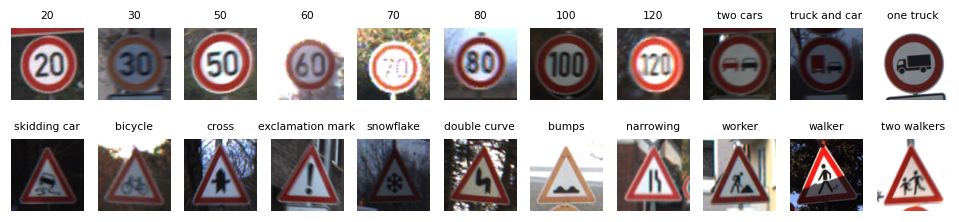

In [2]:
ORDER = ["number", "vehicles", "moving vehicle", "symbol", "road", "people"]
leaves = [(c, v) for o in ORDER for c, v in classes.items() if v["content"] == o]
st = S.load_answers("steps")  # one row per photo: 14,041 photos
ex = st[st.ok].groupby("cls").path.first()
fig, axs = plt.subplots(2, 11, figsize=(11, 2.4))
for a, (c, v) in zip(axs.flat, leaves):
    a.imshow(photo(ex[c])); a.set_title(v["item"], fontsize=7); a.axis("off")
plt.show()

The attributes form a **3-level decision tree**: shape → content → item. Each of the 22 leaves gets an **arbitrary label 1–22**, so the model cannot answer from prior knowledge and has to apply the rules. Labels are re-randomised 5 times and the rules listed in 2 orders, identically for every strategy; each photo is answered under one of these variants.

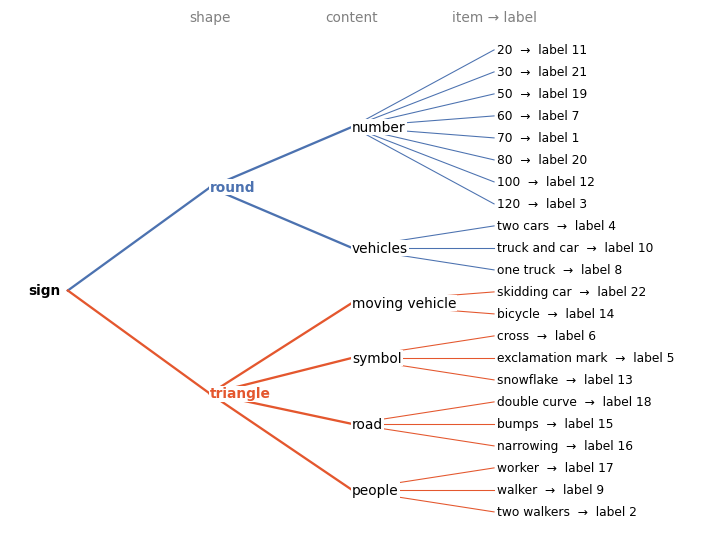

In [3]:
y = {c: -i for i, (c, _) in enumerate(leaves)}
yc = {o: np.mean([y[c] for c, v in leaves if v["content"] == o]) for o in ORDER}
ys = {s: np.mean([yc[o] for o in ORDER if SHAPE_OF[o] == s]) for s in ("round", "triangle")}
col = {"round": "#4C72B0", "triangle": "#E4572E"}
root = np.mean(list(ys.values()))
box = dict(fc="white", ec="none", pad=0.6)
fig, ax = plt.subplots(figsize=(8, 6))
for s, v in ys.items():
    ax.plot([0, 1], [root, v], c=col[s]); ax.text(1, v, s, color=col[s], fontweight="bold", va="center", bbox=box)
for o, v in yc.items():
    ax.plot([1, 2], [ys[SHAPE_OF[o]], v], c=col[SHAPE_OF[o]]); ax.text(2, v, o, va="center", bbox=box)
for c, v in leaves:
    ax.plot([2, 3], [yc[v["content"]], y[c]], c=col[v["shape"]], lw=0.7)
    ax.text(3.02, y[c], f'{v["item"]}  →  label {LABELS[0][c]}', va="center", fontsize=8)
for x, t in zip([1, 2, 3], ["shape", "content", "item → label"]):
    ax.text(x, 1.3, t, ha="center", color="gray")
ax.text(-0.05, root, "sign", ha="right", va="center", fontweight="bold"); ax.set_xlim(-0.4, 4.4); ax.axis("off")
plt.show()

# 2️⃣ How do we write the tree into a prompt?

Every prompt has the same frame: task + attribute definitions → **rules** → answer format → `Sign photo:` + image. The model must report the three attributes it read, then the label. Only the rules block changes. Here are the four strategies on the same tree:

In [4]:
def prompt(fmt, seed=0, order="o1"):
    return (H / f"rulesets/h3L{seed}/prompts/image/{fmt}_{order}.txt").read_text().split("\n")

P0 = prompt("steps")
print("── header (all formats) ──")
print("\n".join(l[:140] + ("…" if len(l) > 140 else "") for l in P0[:6]))
for f in FMTS:
    lines = prompt(f)
    i = next(i for i, l in enumerate(lines) if re.match(r"(Decision|Rules)", l))
    print(f"\n── {NAME[f]} ──\n" + "\n".join(l[:140] for l in lines[i:i + 9]) + "\n  …")
print("\n── answer format (all formats) ──\n" + "\n".join([l for l in P0 if l][-2:]))

── header (all formats) ──
You are given rules that give each traffic sign exactly one label, followed by a cropped photo of a traffic sign. Read the sign's attributes…

Attributes (every sign shows a white face inside a thick red rim):
- shape: round means the outline is a circle; triangle means a triangle with one corner at the top and a flat bottom edge.
- content: number means a number made of black digits; vehicles means one or two cars or trucks drawn on their own, upright; two of them sta…
- item: 20, 30, 50, 60, 70, 80, 100 and 120 mean those digits; one truck means a single truck; two cars means two cars side by side; truck a…

── P1 steps ──
Decision procedure (start at Step A; at each step follow the one condition that matches the sign until you reach a label):

Step A. Determine the shape.
- If shape is round, go to Step B.
- If shape is triangle, go to Step E.

Step B. Determine the content.
- If content is number, go to Step C.
- If content is vehicles, go to Step D.
  …


| | strategy | rules block | to reach a label the model must… |
|---|---|---|---|
| **P1** | lettered steps | Steps A–I, one decision each, with "go to Step X" pointers | follow pointers from step to step |
| **P2** | outline | nested bullets, one level per attribute | descend the indentation |
| **P3** | decision table | HTML table, 22 rows of (shape, content, item, label) | find the matching row |
| **P4** | flat rules | 22 if-then rules, each stating all three attributes | find the matching rule |

All four encode exactly the same tree. Each of the 14,041 photos is answered once under every strategy.

**Metrics.** **Accuracy**: the label is the gold label. **Adherence**: the label is the one the rules give to the attributes *the answer itself reports*, i.e. rule-following, whether or not the photo was read correctly. **Off-tree**: the reported (shape, content, item) is not a path of the tree.

,accuracy,adherence,errors,non-adherent,…of which off-tree,shape jump,same-shape off-tree
P1 steps,0.882,0.980,1651,279,279,202,77
P2 outline,0.883,0.991,1641,124,124,92,32
P3 table,0.883,0.996,1642,50,50,46,4
P4 flat,0.882,0.995,1659,67,67,56,11


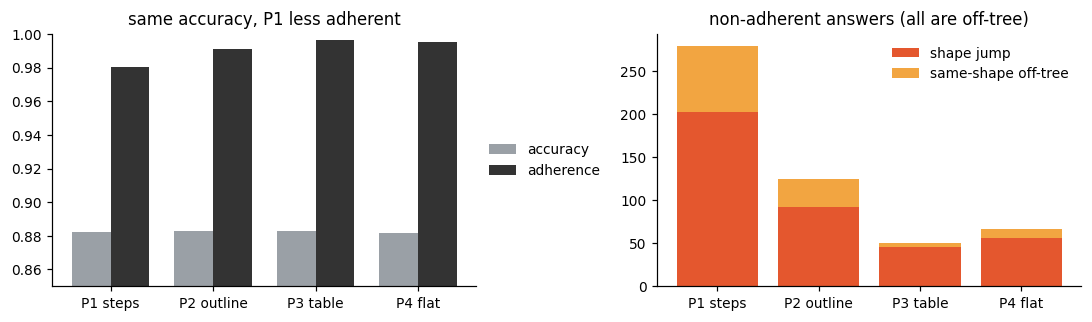

In [5]:
A = {f: S.load_answers(f) for f in FMTS}  # the same 14,041 photos in every format
for d in A.values():
    d["kind"] = [kind(r) for r in d.to_dict("records")]
    d["off_tree"] = [(a, b, c) not in S.leaf_of for a, b, c in zip(d["shape"], d.content, d.item)]
tab = pd.DataFrame({NAME[f]: {"accuracy": d.ok.mean(), "adherence": d.adh.mean(), "errors": (~d.ok).sum(),
                              "non-adherent": (~d.adh).sum(), "…of which off-tree": (d.off_tree & ~d.adh).sum(),
                              "shape jump": (d.kind == "shape jump").sum(),
                              "same-shape off-tree": (d.kind == "same-shape off-tree").sum()}
                    for f, d in A.items()}).T
display(tab.style.format({"accuracy": "{:.3f}", "adherence": "{:.3f}"}, precision=0))

fig, axs = plt.subplots(1, 2, figsize=(10, 3))
x = np.arange(len(FMTS))
for i, m in enumerate(["accuracy", "adherence"]):
    axs[0].bar(x + (i - 0.5) * 0.38, tab[m], 0.38, label=m, color=["#9AA0A6", "#333"][i])
axs[0].set_xticks(x, tab.index); axs[0].set_ylim(0.85, 1.0); axs[0].legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5)); axs[0].set_title("same accuracy, P1 less adherent")
bottom = np.zeros(len(FMTS))
for k in ["shape jump", "same-shape off-tree"]:
    axs[1].bar(x, tab[k], bottom=bottom, color=KC[k], label=k); bottom += tab[k].values
axs[1].set_xticks(x, tab.index); axs[1].legend(frameon=False); axs[1].set_title("non-adherent answers (all are off-tree)")
plt.tight_layout(); plt.show()

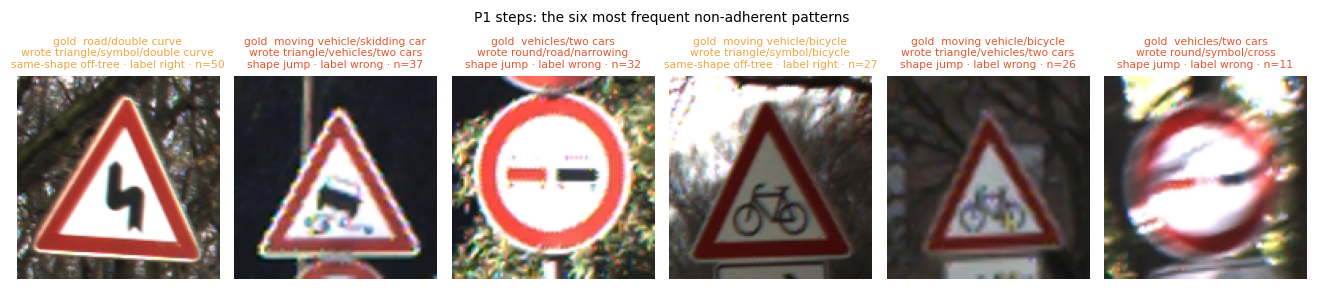

In [6]:
na = A["steps"][~A["steps"].adh].copy()
na["gold"] = [gold(r) for r in na.to_dict("records")]
na["written"] = na.content + "/" + na.item
top = na.groupby(["gold", "written", "kind"]).size().sort_values(ascending=False).head(6)
fig, axs = plt.subplots(1, 6, figsize=(12, 2.9))
for a, ((g, w, k), n) in zip(axs, top.items()):
    r = na[(na.gold == g) & (na.written == w)].iloc[0]
    a.imshow(photo(r.path, 128)); a.axis("off")
    a.set_title(f"gold  {g}\nwrote {r['shape']}/{w}\n{k} · label {'right' if r.ok else 'wrong'} · n={n}",
                fontsize=7, color=KC[k])
plt.suptitle("P1 steps: the six most frequent non-adherent patterns", fontsize=9); plt.tight_layout(); plt.show()
EX = na[(na.gold == "moving vehicle/skidding car") & (na.written == "vehicles/two cars")].iloc[0]  # used in 🔁

**What the results say**

- Accuracy is identical (0.882–0.883), but P1's adherence is lower (0.980 vs 0.991–0.996): 279 rule breaks vs 124 / 50 / 67, with the same number of errors (about 1,650).
- Every rule break is **off-tree**: the reported attributes are not a path, so no label can follow from them. None reports a valid path with another leaf's label.
- Two patterns:
  - **shape jump**: the content comes from the other shape's subtree (a triangle sign reported as `triangle / vehicles / two cars`). Usually a wrong label.
  - **same-shape off-tree**: right shape, but the item belongs to another content (`triangle / symbol / double curve`). Usually the *right* label.
- The label almost always follows the reported item.
- P1 doesn't make more errors. It turns misreadings into off-tree answers where P2 and P3 turn them into wrong but valid leaves.

**Why look inside.** Behaviour shows *that* P1's path breaks, not *where* in the computation. Three hypotheses, which need internal read-outs to tell apart:

| | claim | internal test |
|---|---|---|
| **H1** post-hoc | the leaf is fixed before any attribute is written; the attributes are decoration | is the label decodable before the answer starts? |
| **H2** late slip | internally the gold content leads; the written token flips at the last layers | do failures follow correct answers until late layers? |
| **H3** gate skipped | the item (and label) are chosen without using the written content | does forcing a content move the item? |

# 3️⃣ What we extract

Each logged answer is re-run (same prompt and image) with the model's own answer fed back token by token (teacher forcing). At five **slots** we save the residual stream at every layer (embeddings + 36 layers). A slot is the position whose output is the first token of the next value: the model is *about to write* it. We also run counterfactuals: force a value into the answer and see what the model writes next.

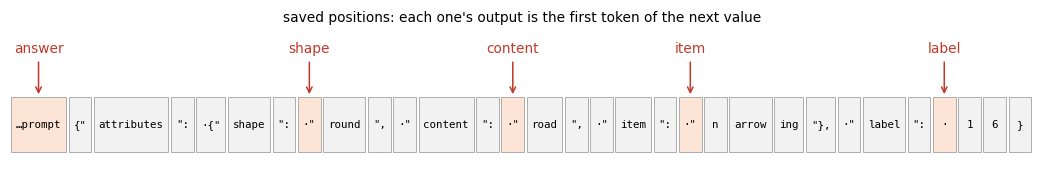

,set,what,n
0,steps_na,every non-adherent P1 answer,279
1,steps_ctl,"adherent P1 answers, same class / rule set / o...",277
2,paired,the steps_na photos answered under P2 and P3,558


hidden/<set>.npy: (279, 9, 5, 4096) float16  = (answers, layers 4, 8, …, 36, positions, d_model)
per-answer fields: ['fmt', 'seed', 'order', 'cls', 'pred', 'label', 'ok', 'adh', 'shape', 'content', 'item', 'repro', 'tf_tokens', 'tf_logprob', 'tf_rank', 'tf_argmax_ok', 'content_lp', 'content_lens', 'item_lp', 'label_lp', 'cf_content', 'cf_item', 'positions']


In [7]:
NA, CTL, PAIRED = jl("steps_na"), jl("steps_ctl"), jl("paired")
r = NA[0]; P = r["positions"]
cells_ = ["…prompt"] + r["tf_tokens"]
idx = {k: v - P["answer"] for k, v in P.items()}
fig, ax = plt.subplots(figsize=(12, 1.5)); x = 0
for i, t in enumerate(cells_):
    w = max(len(t), 2) * 0.1 + 0.15
    hit = [k for k, v in idx.items() if v == i]
    ax.add_patch(plt.Rectangle((x, 0), w, 1, fc="#FCE4D6" if hit else "#F2F2F2", ec="#999", lw=0.5))
    ax.text(x + w / 2, 0.5, t.replace(" ", "·"), ha="center", va="center", fontsize=7, family="monospace")
    if hit:
        ax.annotate(hit[0], (x + w / 2, 1), (x + w / 2, 1.8), ha="center", color="#C0392B",
                    arrowprops=dict(arrowstyle="->", color="#C0392B"))
    x += w + 0.04
ax.set_xlim(0, x); ax.set_ylim(-0.1, 2.2); ax.axis("off")
ax.set_title("saved positions: each one's output is the first token of the next value", fontsize=9); plt.show()

h = np.load(OUT / "hidden/steps_na.npy", mmap_mode="r")
display(pd.DataFrame([
    ("steps_na", "every non-adherent P1 answer", len(NA)),
    ("steps_ctl", "adherent P1 answers, same class / rule set / order", len(CTL)),
    ("paired", "the steps_na photos answered under P2 and P3", len(PAIRED)),
], columns=["set", "what", "n"]))
print("hidden/<set>.npy:", h.shape, h.dtype, " = (answers, layers 4, 8, …, 36, positions, d_model)")
print("per-answer fields:", [k for k in r if k not in ("raw", "regen", "path")])

`content_lp` / `content_lens`: log-probs of the 6 contents at the content slot (output / every layer) · `cf_content`: force each content, read the generated item + label · `cf_item`: force an item (gold, sibling-branch, other-shape), read the label.

# 4️⃣ Content slot: logit lens & forcing

**Logit lens**: push an intermediate layer's residual through the final norm and unembedding to see which content it already favours. Failures are compared with correctly read photos of the same class.

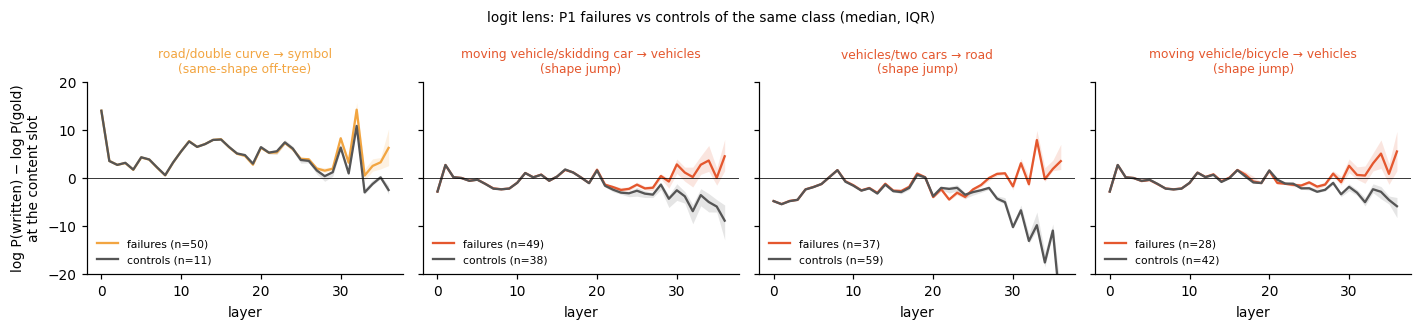

In [8]:
wrong = [r for r in NA if r["content"] != classes[r["cls"]]["content"]]
pat = lambda r: (gold(r), r["content"])
pats = [p for p, n in Counter(map(pat, wrong)).most_common(4)]
fig, axs = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for a, (g, w) in zip(axs, pats):
    fail = [r for r in wrong if pat(r) == (g, w)]
    ctl = [r for r in CTL if gold(r) == g and r["content"] == classes[r["cls"]]["content"]]  # same class, read right
    gc = g.split("/")[0]
    for rs, c, lab in ((fail, KC[kind(fail[0])], f"failures (n={len(fail)})"), (ctl, "#555", f"controls (n={len(ctl)})")):
        m = np.array([np.subtract(r["content_lens"][w], r["content_lens"][gc]) for r in rs])
        a.plot(np.median(m, 0), color=c, label=lab)
        a.fill_between(range(37), *np.percentile(m, [25, 75], 0), color=c, alpha=0.15, lw=0)
    a.axhline(0, c="k", lw=0.5); a.set_title(f"{g} → {w}\n({kind(fail[0])})", fontsize=8, color=KC[kind(fail[0])])
    a.set_xlabel("layer"); a.legend(fontsize=7, frameon=False, loc="lower left")
axs[0].set_ylabel("log P(written) − log P(gold)\nat the content slot"); axs[0].set_ylim(-20, 20)
plt.suptitle("logit lens: P1 failures vs controls of the same class (median, IQR)", fontsize=9); plt.tight_layout(); plt.show()

**Reading.** Early-layer rankings are the **same for failures and controls** (a prior over contents, not the photo). In the *double curve → symbol* panel even correctly-read controls favour "symbol" until ~L33. Failures split from controls only in the **last ~8 layers**, in every pattern. So the logit lens alone cannot separate H2 from H3. Forcing (below) and knockout can.

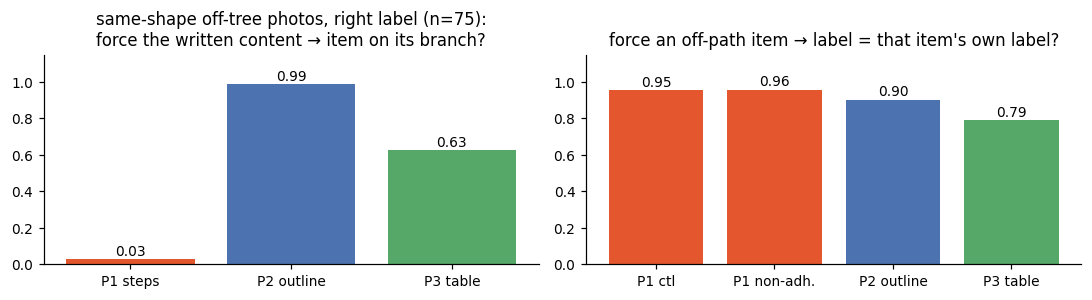

In [9]:
def item_on_branch(c, cont):
    return cont.split('"')[0] in BRANCH[c]


cheat = {r["path"]: r["content"] for r in NA if kind(r) == "same-shape off-tree" and r["ok"]}
grp = {"P1 steps": [r for r in NA if r["path"] in cheat],
       "P2 outline": [r for r in PAIRED if r["fmt"] == "outline" and r["path"] in cheat],
       "P3 table": [r for r in PAIRED if r["fmt"] == "table" and r["path"] in cheat]}
forced_c = {g: np.mean([item_on_branch(cheat[r["path"]], r["cf_content"][cheat[r["path"]]]) for r in rs
                        if cheat[r["path"]] in r["cf_content"]]) for g, rs in grp.items()}


def label_follows_item(recs):  # forced OFF-path item: is the label that item's own leaf label?
    hit = []
    for r in recs:
        for x, cont in r["cf_item"].items():
            m = re.match(r"\s*(\d+)", cont)
            if x not in BRANCH.get(r["content"], []) and m:
                hit.append(int(m.group(1)) == LABELS[r["seed"]][S.item_leaf[x]])
    return np.mean(hit)


forced_i = {"P1 ctl": label_follows_item(CTL), "P1 non-adh.": label_follows_item(NA),
            "P2 outline": label_follows_item([r for r in PAIRED if r["fmt"] == "outline"]),
            "P3 table": label_follows_item([r for r in PAIRED if r["fmt"] == "table"])}
fig, axs = plt.subplots(1, 2, figsize=(10, 2.8))
axs[0].bar(forced_c.keys(), forced_c.values(), color=[FC["steps"], FC["outline"], FC["table"]])
axs[0].set_title(f"same-shape off-tree photos, right label (n={len(cheat)}):\nforce the written content → item on its branch?")
axs[1].bar(forced_i.keys(), forced_i.values(), color=[FC["steps"], FC["steps"], FC["outline"], FC["table"]])
axs[1].set_title("force an off-path item → label = that item's own label?")
for a in axs:
    a.set_ylim(0, 1.15)
    for p in a.patches:
        a.text(p.get_x() + p.get_width() / 2, p.get_height() + 0.02, f"{p.get_height():.2f}", ha="center")
plt.tight_layout(); plt.show()

**Takeaway.** P2/P3 let a forced content constrain the item; P1 writes the image's item anyway (**content gate weak in P1**). In every format the label is looked up from the item, whatever the content says (strongest in P1, weakest in P3).

# 5️⃣ Probes: the dead end

A **probe** is a linear classifier on the saved residuals. Two questions: (a) is the label already formed before anything is written (**H1**)? (b) can a probe flag an off-tree answer before it happens? **AUC** = ROC area (0.5 chance, 1 perfect). Every split holds out one label assignment, so a photo never meets itself in training.

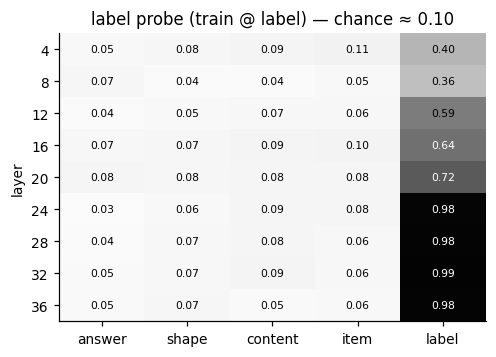

In [10]:
LAY = [4, 8, 12, 16, 20, 24, 28, 32, 36]; POS = ["answer", "shape", "content", "item", "label"]


def hidden(set_name, recs):  # stored for the layers in LAY only, in the order of <set_name>.jsonl
    X = np.load(OUT / "hidden" / f"{set_name}.npy").astype(np.float32)  # (n, layers, 5, 4096)
    assert len(X) == len(recs)
    return X


RS = NA + CTL
XS = np.concatenate([hidden("steps_na", NA), hidden("steps_ctl", CTL)])  # P1: non-adherent + controls
XP = hidden("paired", PAIRED)                                              # P2 / P3 on the same photos

# (a) label probe trained at the label position, tested at every earlier position
y = np.array([str(json.loads(r["raw"])["label"]) for r in RS])
keep = np.isin(y, [c for c, n in Counter(y).items() if n >= 5]); Xk, yk = XS[keep], y[keep]
acc = np.zeros((len(LAY), len(POS)))
for tr, te in StratifiedKFold(5, shuffle=True, random_state=0).split(yk, yk):
    for li in range(len(LAY)):
        m = D.clf().fit(Xk[tr, li, 4], yk[tr])
        acc[li] += [m.score(Xk[te, li, p], yk[te]) for p in range(len(POS))]
acc /= 5
fig, ax = plt.subplots(figsize=(5, 3.4))
im = ax.imshow(acc, cmap="Greys", vmin=0, vmax=1, aspect="auto")
for (i, j), v in np.ndenumerate(acc):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="w" if v > 0.6 else "k")
ax.set_xticks(range(len(POS)), POS); ax.set_yticks(range(len(LAY)), LAY); ax.set_ylabel("layer")
ax.set_title(f"label probe (train @ label) — chance ≈ {Counter(yk).most_common(1)[0][1] / len(yk):.2f}")
plt.show()

The label is readable only at the label position; at `answer` the transfer probe is at chance (**H1 not supported**; a direct probe there gets 0.32–0.35, no more than the gold leaf and the label assignment give).

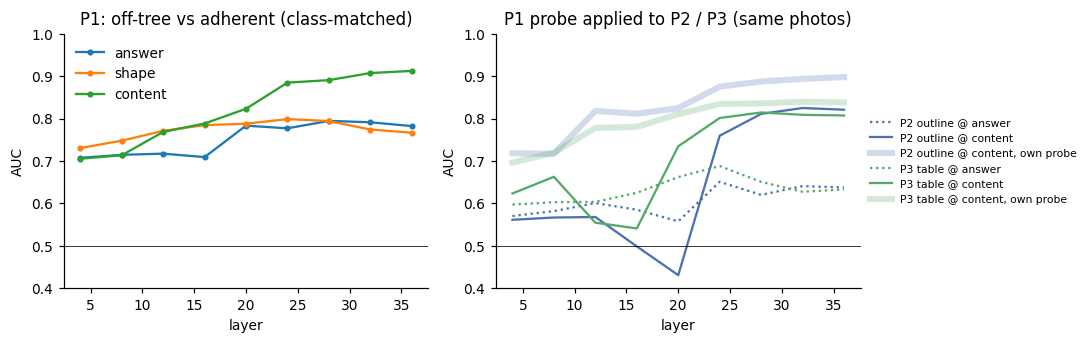

In [11]:
# (b) off-tree vs adherent, leave-one-rule-set-out AUC
yb = np.array([not r["adh"] for r in RS], int); sd = np.array([r["seed"] for r in RS])
auc_s = np.array([[D.loro(XS[:, li, p], yb, sd) for p in range(3)] for li in range(len(LAY))])
tr_ = {}
for f in ("outline", "table"):
    ix = [i for i, r in enumerate(PAIRED) if r["fmt"] == f]
    yt = np.array([not PAIRED[i]["adh"] for i in ix], int); st_ = np.array([PAIRED[i]["seed"] for i in ix])
    tr_[f] = {p: ([D.loro(XS[:, li, p], yb, sd, Xt=XP[ix, li, p], yt=yt, seed_t=st_) for li in range(len(LAY))],
                  [D.loro(XP[ix, li, p], yt, st_) for li in range(len(LAY))]) for p in (0, 2)}
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
for j, p in enumerate(POS[:3]):
    axs[0].plot(LAY, auc_s[:, j], marker="o", ms=3, label=p)
axs[0].set_title("P1: off-tree vs adherent (class-matched)"); axs[0].set_ylim(0.4, 1); axs[0].legend(frameon=False)
for f, d in tr_.items():
    for p, ls in ((0, ":"), (2, "-")):
        axs[1].plot(LAY, d[p][0], ls=ls, color=FC[f], label=f"{NAME[f]} @ {POS[p]}")
    axs[1].plot(LAY, d[2][1], color=FC[f], alpha=0.25, lw=4, label=f"{NAME[f]} @ content, own probe")
axs[1].set_title("P1 probe applied to P2 / P3 (same photos)"); axs[1].set_ylim(0.4, 1)
axs[1].legend(fontsize=7, frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
for a in axs:
    a.axhline(0.5, c="k", lw=0.5); a.set_xlabel("layer"); a.set_ylabel("AUC")
plt.tight_layout(); plt.show()

**Why we moved on.** The residual flags failures (AUC ≈ 0.78 at `answer`, ≈ 0.9 at `content`), but the early signal does not transfer across formats (≈ 0.6). It mostly says *this photo is hard*, and decodable is not the same as used. Next: causal tests that ask **which prompt span** the failing content is read from.

# 6️⃣ Attention knockout

Probes show what is *decodable*, not what is *used*. **Knockout**: the answer positions are blocked from attending to one span of the prompt (the other shape's content lines, the own shape's, the image, the glossary, …) in layers 0–11, 12–23 or 24–35. A **flip** counts for failures when the gold value becomes the top choice (**repair**), and for correct controls when the gold value loses it (**harm**).

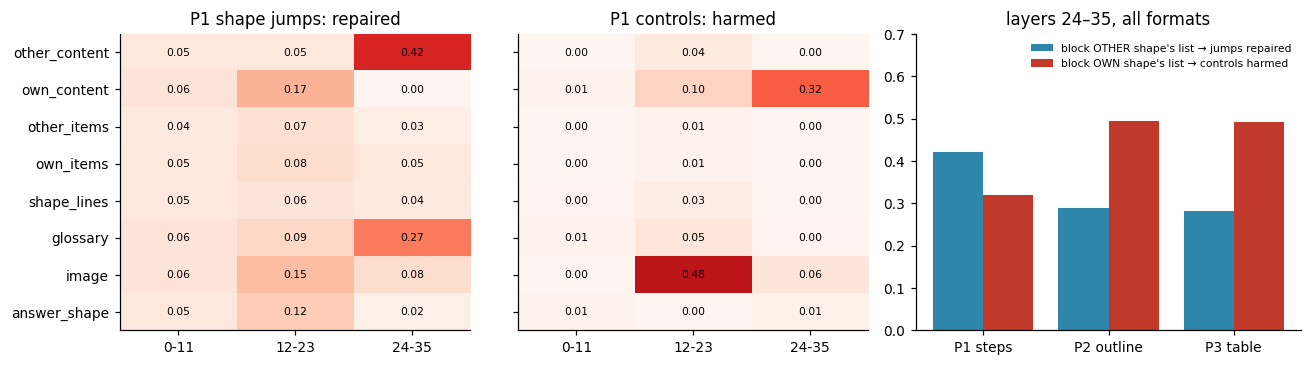

In [12]:
KO1, KO2 = jl("knockout_content"), jl("knockout_content2")


def ko(rows, cond, m=KS.m_c, f=KS.f_c):
    d, fl = [], []
    for r in rows:
        nm = [n.replace("_rows", "_content") for n in r["names"]]
        if cond in nm:
            i = nm.index(cond); d.append(m(r, r["lp"][i]) - m(r, r["lp"][0])); fl.append(f(r, r["lp"][i]))
    return (np.mean(d), np.mean(fl)) if d else (np.nan, np.nan)


SP = ["other_content", "own_content", "other_items", "own_items", "shape_lines", "glossary", "image", "answer_shape"]
LR = ["0-11", "12-23", "24-35"]
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4), gridspec_kw=dict(width_ratios=[1, 1, 1.1]))
for a, g, t in [(axs[0], "cross_wrong", "P1 shape jumps: repaired"), (axs[1], "ctl_right_content", "P1 controls: harmed")]:
    M = np.array([[ko([r for r in KO1 if r["group"] == g], f"{s}@{l}")[1] for l in LR] for s in SP])
    a.imshow(M, cmap="Reds", vmin=0, vmax=0.6, aspect="auto")
    for (i, j), v in np.ndenumerate(M):
        a.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7)
    a.set_xticks(range(3), LR); a.set_yticks(range(len(SP)), SP if a is axs[0] else []); a.set_title(t)
rows = {"P1 steps": (KO1, "cross_wrong", "ctl_right_content"), "P2 outline": (KO2, "outline_cross_wrong", "outline_ctl"),
        "P3 table": (KO2, "table_cross_wrong", "table_ctl")}
x = np.arange(3)
rep = [ko([r for r in src if r["group"] == g], "other_content@24-35")[1] for src, g, _ in rows.values()]
harm = [ko([r for r in src if r["group"] == c], "own_content@24-35")[1] for src, _, c in rows.values()]
axs[2].bar(x - 0.2, rep, 0.4, color="#2E86AB", label="block OTHER shape's list → jumps repaired")
axs[2].bar(x + 0.2, harm, 0.4, color="#C0392B", label="block OWN shape's list → controls harmed")
axs[2].set_xticks(x, rows.keys()); axs[2].set_ylim(0, 0.7); axs[2].legend(fontsize=7, frameon=False)
axs[2].set_title("layers 24–35, all formats")
plt.tight_layout(); plt.show()

**Shape jumps.** Layers 12–23 read the **image**; layers 24–35 **retrieve a content name from the rules' content lines**. A shape jump is that late retrieval landing on the other shape's list; the written shape barely restricts which list is read. Same mechanism in P1–P3; P1 just falls into it more often (202 vs 92 vs 46).

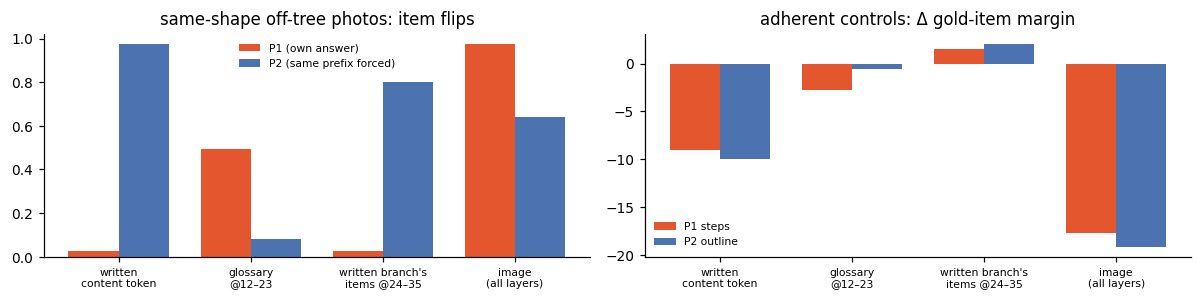

In [13]:
KI = jl("knockout_item"); KIc = [r for r in jl("knockout_item_ctl") if classes[r["cls"]]["item"] not in ("100", "120")]
CONDS = {"written\ncontent token": "answer_content@all", "glossary\n@12–23": "glossary@12-23",
         "written branch's\nitems @24–35": "prefixed_items@24-35", "image\n(all layers)": "image@all"}
fig, axs = plt.subplots(1, 2, figsize=(11, 2.8))
x = np.arange(len(CONDS))
for j, (g, f, lab) in enumerate([("steps_right_na", "steps", "P1 (own answer)"), ("outline_forced", "outline", "P2 (same prefix forced)")]):
    axs[0].bar(x + (j - 0.5) * 0.38, [ko([r for r in KI if r["group"] == g], c, KS.m_i, KS.f_i)[1] for c in CONDS.values()],
               0.38, color=FC[f], label=lab)
    g2 = "steps_ctl" if f == "steps" else "outline_ctl"
    axs[1].bar(x + (j - 0.5) * 0.38, [ko([r for r in KIc if r["group"] == g2], c, KS.m_i, KS.f_i)[0] for c in CONDS.values()],
               0.38, color=FC[f], label=NAME[f])
axs[0].set_title("same-shape off-tree photos: item flips"); axs[1].set_title("adherent controls: Δ gold-item margin")
for a in axs:
    a.set_xticks(x, CONDS.keys(), fontsize=7); a.legend(fontsize=7, frameon=False)
plt.tight_layout(); plt.show()

**Same-shape off-tree.** P2 is content-gated (block the written content → 97 % switch to the off-branch gold item). P1 names the item from the image + glossary (glossary block flips ~half; content token ~3 %). In ordinary answers both formats do use the content (similar Δ), so P1's gate is **weaker, not absent**: it loses only when content and image disagree.

# 7️⃣ Heads

Which attention heads read the other shape's list? Per head: attention mass from the content slot onto that list × **direct logit attribution** (DLA; the head's direct push toward the written content). The top 12 are picked on 3 of the 5 label assignments. Then only those heads are blocked, on the other 2, and compared with random sets of 12 heads.

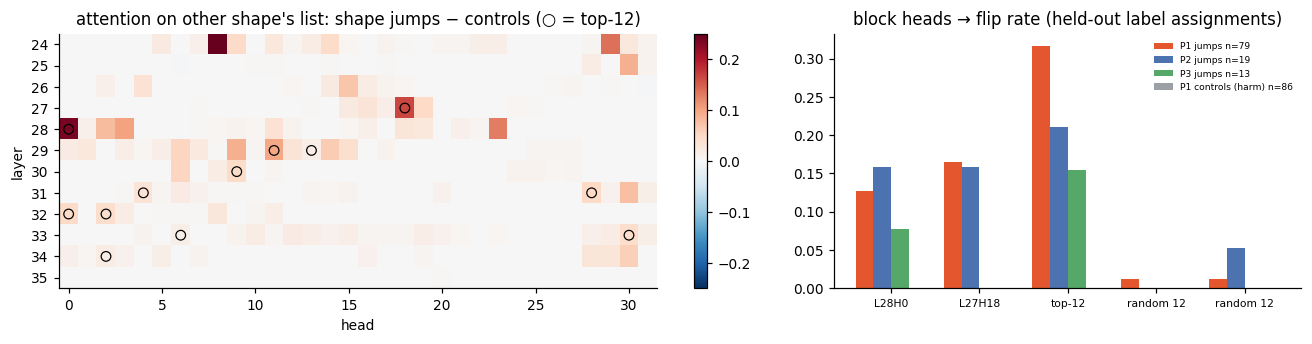

In [14]:
HA = jl("heads_content_attr")
cand = json.loads((OUT / "heads_content_candidates.json").read_text())["top"]
mass = {g: np.mean([a["mass"]["other_list"] for a in HA if a["group"] == g], 0) for g in ("steps_cross_wrong", "steps_ctl")}
diff = (mass["steps_cross_wrong"] - mass["steps_ctl"])[24:36]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.2), gridspec_kw=dict(width_ratios=[1.6, 1]))
im = axs[0].imshow(diff, cmap="RdBu_r", vmin=-0.25, vmax=0.25, aspect="auto")
for l, h in cand:
    axs[0].scatter(h, l - 24, s=40, facecolors="none", edgecolors="k", lw=0.8)
axs[0].set_yticks(range(12), range(24, 36)); axs[0].set_xlabel("head"); axs[0].set_ylabel("layer")
axs[0].set_title("attention on other shape's list: shape jumps − controls (○ = top-12)"); plt.colorbar(im, ax=axs[0])

HV = [r for r in jl("heads_content_verify") if r["seed"] >= 3]  # held-out rule sets
conds = ["L28H0", "L27H18", "top_joint", "random_joint_1", "random_joint_2"]
groups = [("steps_cross_wrong", "P1 jumps", FC["steps"]), ("outline_cross_wrong", "P2 jumps", FC["outline"]),
          ("table_cross_wrong", "P3 jumps", FC["table"]), ("steps_ctl", "P1 controls (harm)", "#9AA0A6")]
x = np.arange(len(conds))
for j, (g, lab, c) in enumerate(groups):
    rs = [r for r in HV if r["group"] == g]
    axs[1].bar(x + (j - 1.5) * 0.2, [np.mean([KS.f_c(r, r["lp"][r["names"].index(k)]) for r in rs]) for k in conds],
               0.2, color=c, label=f"{lab} n={len(rs)}")
axs[1].set_xticks(x, ["L28H0", "L27H18", "top-12", "random 12", "random 12"], fontsize=7)
axs[1].set_title("block heads → flip rate (held-out label assignments)"); axs[1].legend(fontsize=6, frameon=False)
plt.tight_layout(); plt.show()

A small, format-general set of late heads (L27H18, L28H0, …) reads the wrong list. Blocking the 12 jointly repairs about a third of held-out P1 jumps at no cost to controls; random sets do nothing. Their attention mass is elevated in failures, so it is a candidate **failure detector**.

# 8️⃣ Detector scan

If a few heads cause shape jumps, their attention should flag them. For **every** answer in P1–P4 (56,164), we record each head's attention from the content slot onto the other / own shape's rule lines, before the content is written. **Hard negatives** are rule-following answers on photos that fail under another strategy (same difficulty). Off-tree answers are rare (0.3–2 %), so besides ROC AUC we report **average precision** (AP), which accounts for prevalence.

scan: 56,164 / 56,164 answers


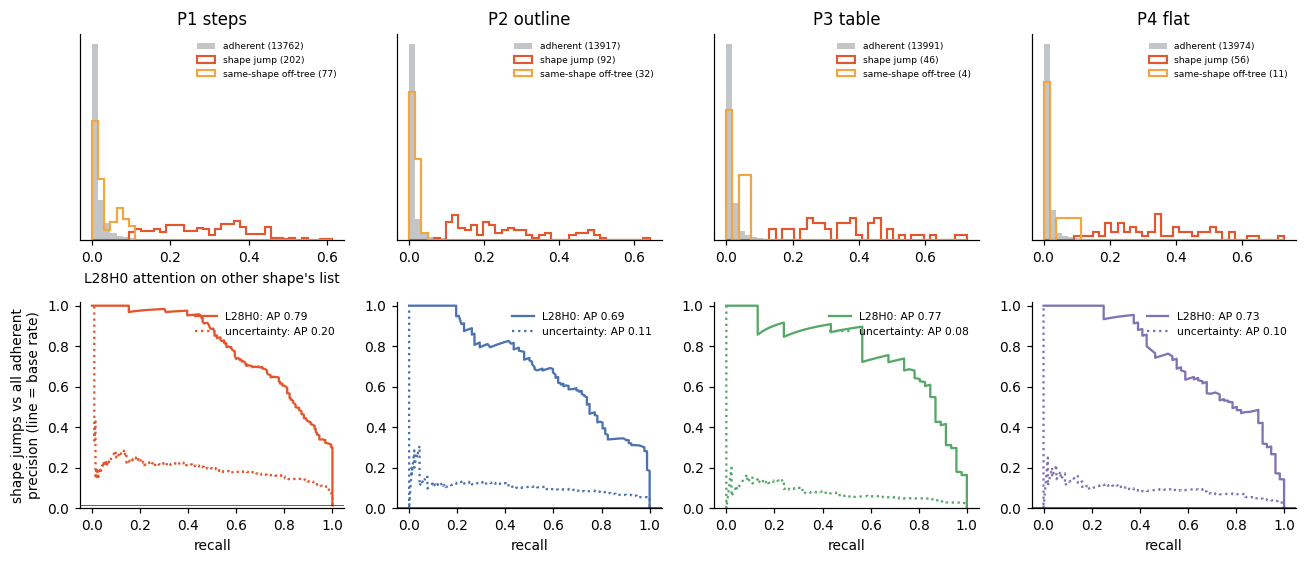

In [15]:
def scan_rows():  # slim copy of the scan: L28H0 only (the full file holds all heads of layers 20-35)
    with open(OUT / "scan_content.jsonl") as f:
        for line in f:
            r = json.loads(line); v = np.array(list(r["content_lp"].values()))
            yield {"fmt": r["fmt"], "path": r["path"], "kind": kind(r), "hard": r["block"] == "enriched",
                   "seed": r["seed"], "L28H0": r["L28H0"], "uncertainty": 1 - np.exp(v.max() - np.logaddexp.reduce(v))}


df = pd.DataFrame(scan_rows())
print(f"scan: {len(df):,} / 56,164 answers")

fig, axs = plt.subplots(2, 4, figsize=(12, 5.2))
for j, f in enumerate(FMTS):
    d = df[df.fmt == f]; bins = np.linspace(0, d.L28H0.max(), 40)
    for k, c in KC.items():
        v = d[d.kind == k].L28H0
        axs[0, j].hist(v, bins, density=True, histtype="stepfilled" if k == "adherent" else "step", color=c, lw=1.4,
                       alpha=0.6 if k == "adherent" else 1, label=f"{k} ({len(v)})")
    axs[0, j].set_title(NAME[f]); axs[0, j].legend(fontsize=6, frameon=False); axs[0, j].set_yticks([])
    x = d[d.kind.isin(["adherent", "shape jump"])]; yy = (x.kind == "shape jump").values
    for s, ls in (("L28H0", "-"), ("uncertainty", ":")):
        pr, rc, _ = precision_recall_curve(yy, x[s])
        axs[1, j].plot(rc, pr, ls, color=FC[f], label=f"{s}: AP {average_precision_score(yy, x[s]):.2f}")
    axs[1, j].axhline(yy.mean(), c="k", lw=0.4); axs[1, j].set_ylim(0, 1.02)
    axs[1, j].legend(fontsize=7, frameon=False, loc="upper right"); axs[1, j].set_xlabel("recall")
axs[0, 0].set_xlabel("L28H0 attention on other shape's list")
axs[1, 0].set_ylabel("shape jumps vs all adherent\nprecision (line = base rate)")
plt.tight_layout(); plt.show()

rows = {}
for f in FMTS:
    d = df[df.fmt == f]
    for pk, nn, neg, held in (("shape jump", "all adherent", ~df.hard | df.hard, False),
                              ("shape jump", "all adherent, rule sets 3–4", ~df.hard | df.hard, True),
                              ("shape jump", "hard negatives", df.hard, False),
                              ("same-shape off-tree", "all adherent", ~df.hard | df.hard, False),
                              ("same-shape off-tree", "hard negatives", df.hard, False)):
        x = d[((d.kind == pk) | ((d.kind == "adherent") & neg[d.index])) & ((d.seed >= 3) | (not held))]
        yy = (x.kind == pk).values
        for s in ("L28H0", "uncertainty"):
            rows.setdefault((pk, nn, "AUC", s), {})[NAME[f]] = roc_auc_score(yy, x[s])
            if nn == "all adherent" and pk == "shape jump":
                rows.setdefault((pk, nn, "AP", s), {})[NAME[f]] = average_precision_score(yy, x[s])
display(pd.DataFrame(rows).T.style.format("{:.2f}")
        .background_gradient(cmap="RdYlGn", vmin=0.2, vmax=1))

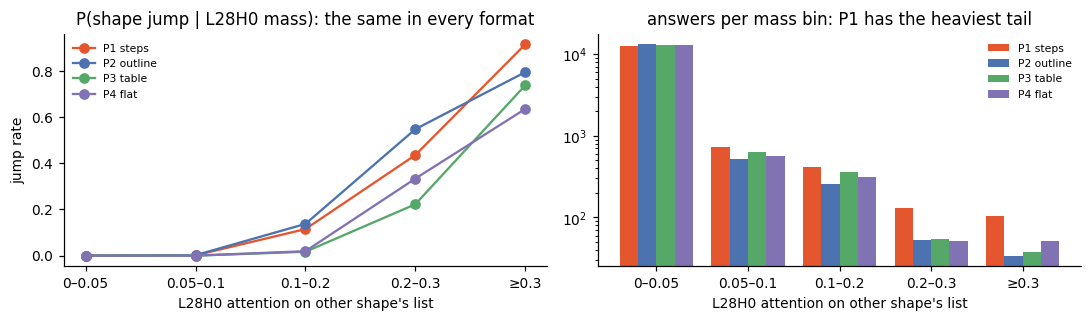

photos that jump only under P1 (n=143): median L28H0 mass 0.29 under P1, 0.13 under P2 on the same photos; answers with mass ≥ 0.2: P1 steps 236, P2 outline 87, P3 table 92, P4 flat 103


In [16]:
# Why more jumps under P1? Same span type in P1 and P2 (the "content is c" lines), so their masses compare.
BINS = [0, 0.05, 0.1, 0.2, 0.3, 1.01]
fig, axs = plt.subplots(1, 2, figsize=(10, 3))
xb = np.arange(len(BINS) - 1); lab = [f"{a:g}–{b:g}" if b < 1 else f"≥{a:g}" for a, b in zip(BINS, BINS[1:])]
for j, f in enumerate(FMTS):
    d = df[df.fmt == f]; g = d.groupby(pd.cut(d.L28H0, BINS, right=False), observed=False).kind
    axs[0].plot(xb, g.apply(lambda s: (s == "shape jump").mean()), marker="o", color=FC[f], label=NAME[f])
    axs[1].bar(xb + (j - 1.5) * 0.2, g.size(), 0.2, color=FC[f], label=NAME[f])
axs[0].set_title("P(shape jump | L28H0 mass): the same in every format"); axs[0].set_ylabel("jump rate")
axs[1].set_title("answers per mass bin: P1 has the heaviest tail"); axs[1].set_yscale("log")
for a in axs:
    a.set_xticks(xb, lab); a.set_xlabel("L28H0 attention on other shape's list"); a.legend(fontsize=7, frameon=False)
plt.tight_layout(); plt.show()

w = df[df.fmt.isin(["steps", "outline"])].pivot(index="path", columns="fmt", values=["L28H0", "kind"])
only = (w.kind.steps == "shape jump") & (w.kind.outline != "shape jump")
print(f"photos that jump only under P1 (n={only.sum()}): median L28H0 mass {w.L28H0.steps[only].median():.2f} under P1, "
      f"{w.L28H0.outline[only].median():.2f} under P2 on the same photos; answers with mass ≥ 0.2: "
      + ", ".join(f"{NAME[f]} {(df[df.fmt == f].L28H0 >= 0.2).sum()}" for f in FMTS))

**Takeaway (full scan).**

- **One untrained head flags shape jumps in every format.** AUC is 0.99–1.00, including the held-out label assignments, and 0.88–0.98 against hard negatives. Average precision is 0.69–0.79, against 0.08–0.20 for the output's uncertainty: at a prevalence of 0.3–1.5 % the AUC hides that gap.
- **Same-shape off-tree answers don't reach the other list** (AUC 0.14–0.20 against hard negatives). They come from a separate mechanism (6️⃣).
- **P1 reaches the other list more often; it does not convert that reach into jumps more readily.** The jump rate per mass bin is about the same in every format, but P1 has 236 answers at ≥ 0.2 against 87–103 elsewhere. The cause lies upstream of L28H0 (9️⃣).

# 9️⃣ Route knockout: what lets P1's content slot reach the other list?

P1 reaches a content list through a **pointer chain**: `- If shape is triangle, go to Step E.` → `Step E. Determine the content.` → the content lines. P2 indents the list directly under `- If shape is triangle:`. If the slot finds "its" list through that route, then blocking the **own** route should push attention to the other list and harm controls, and blocking the **other** route should repair jumps.

Spans, own vs other shape. P1: `shape_cond` (`- If shape is s,`), `shape_ptr` (`go to Step X.`), `header` (`Step X. Determine the content.`), `route` = pointer + header. P2: `shape_line`. Reference spans for both: `own_content` / `other_content`. Each span is blocked from the answer positions in layers 0–11, 12–23, 24–35 or all layers.

Groups per format: every shape jump, **near misses** (adherent answers with L28H0 ≥ 0.2) and class-matched **controls** (right content, L28H0 < 0.05). Runs are batch 1 with eager attention; the baseline reproduces the scan exactly. Read-outs: **flip rate** (a jump is repaired when the gold content becomes top-1, counted only on jumps whose batch-1 baseline still writes the jumped content (some logged jumps don't reproduce outside batch-32 decoding); a near miss or control flips when its top-1 changes) and the **change in L28H0's mass on the other list**.

Data: `route_content.jsonl`.

route knockout: 671 / 671 answers; jumps reproduced at batch 1: steps 171/202, outline 79/92


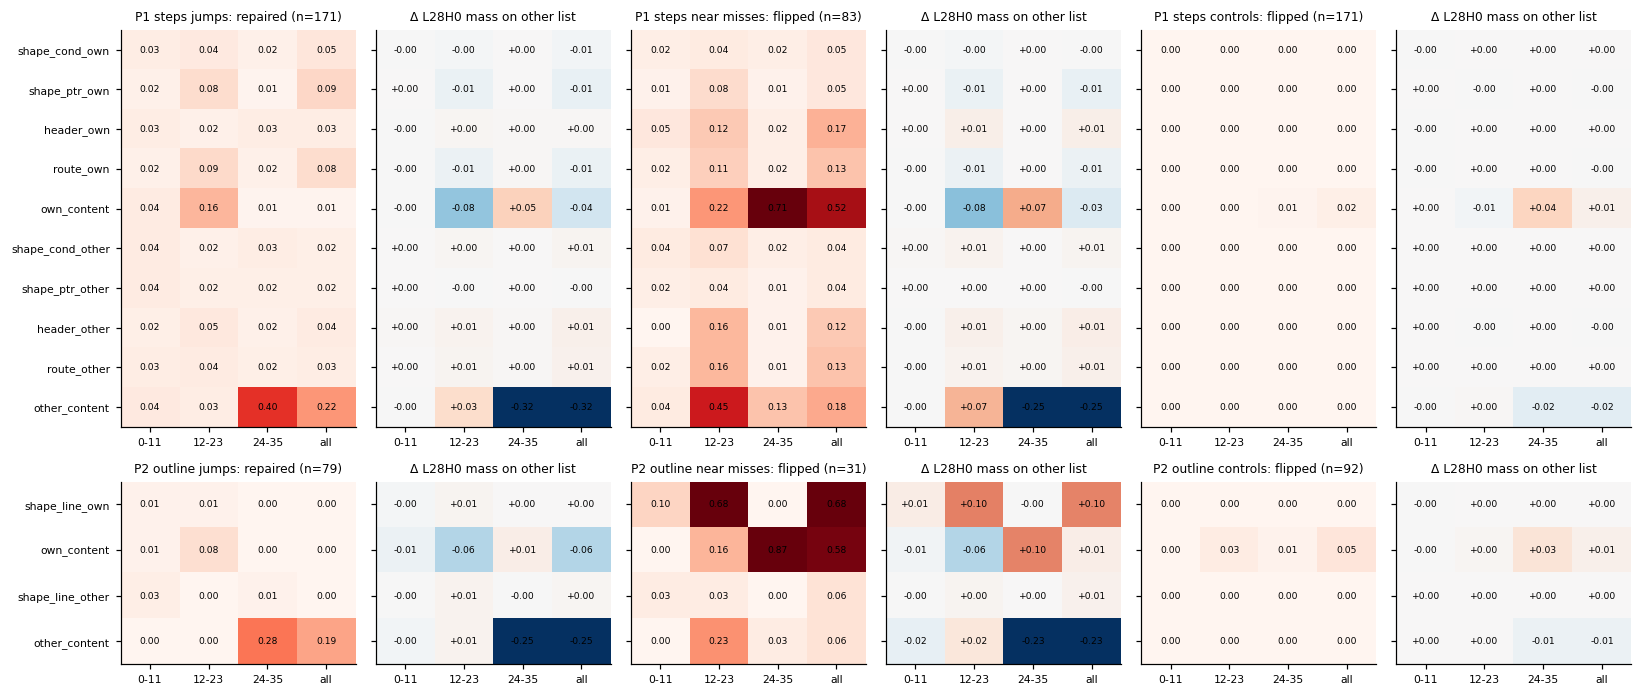

In [17]:
def reproduced(r):  # a jump whose batch-1 baseline still writes the jumped content
    return not r["group"].endswith("jump") or int(np.argmax(r["lp"][0])) == r["cands"].index(r["content"])


RO = jl("route_content")
print(f"route knockout: {len(RO)} / 671 answers; jumps reproduced at batch 1: "
      + ", ".join(f"{f} {sum(map(reproduced, J))}/{len(J)}" for f in ("steps", "outline")
                  for J in [[r for r in RO if r["group"] == f"{f}_jump"]]))


def route_tab(rows, metric):
    out = {}
    for r in rows:
        lp = np.array(r["lp"]); top = lp.argmax(1); m = np.array(r["mass"]["L28H0:other_list"])
        gold_i = r["cands"].index(classes[r["cls"]]["content"])
        for i, n in enumerate(r["names"][1:], 1):
            s, lr = n.split("@")
            v = (top[i] == gold_i) if metric == "flip" and r["group"].endswith("jump") else \
                (top[i] != top[0]) if metric == "flip" else m[i] - m[0]
            out.setdefault(s, {}).setdefault(lr, []).append(v)
    agg = np.mean if metric == "flip" else np.median
    return pd.DataFrame({s: {lr: agg(v) for lr, v in d.items()} for s, d in out.items()}).T[list(KO_LR)]


KO_LR = ["0-11", "12-23", "24-35", "all"]
ORDER_SP = {"steps": ["shape_cond_own", "shape_ptr_own", "header_own", "route_own", "own_content",
                      "shape_cond_other", "shape_ptr_other", "header_other", "route_other", "other_content"],
            "outline": ["shape_line_own", "own_content", "shape_line_other", "other_content"]}
GR = [("jump", "jumps: repaired"), ("near", "near misses: flipped"), ("ctl", "controls: flipped")]
fig, axs = plt.subplots(2, 6, figsize=(15, 6.4), gridspec_kw=dict(height_ratios=[10, 4.6]))
for i, f in enumerate(["steps", "outline"]):
    for j, (g, t) in enumerate(GR):
        rs = [r for r in RO if r["group"] == f"{f}_{g}" and reproduced(r)]
        for k, (metric, cmap, lim) in enumerate([("flip", "Reds", (0, 0.6)), ("dmass", "RdBu_r", (-0.2, 0.2))]):
            a = axs[i, 2 * j + k]
            if not rs:
                a.axis("off"); continue
            M_ = route_tab(rs, metric).reindex(ORDER_SP[f])
            a.imshow(M_.values, cmap=cmap, vmin=lim[0], vmax=lim[1], aspect="auto")
            for (y_, x_), v in np.ndenumerate(M_.values):
                a.text(x_, y_, f"{v:+.2f}" if metric == "dmass" else f"{v:.2f}", ha="center", va="center", fontsize=6)
            a.set_xticks(range(4), KO_LR, fontsize=7)
            a.set_yticks(range(len(M_)), M_.index if j == 0 and k == 0 else [], fontsize=7)
            a.set_title(f"{NAME[f]} {t} (n={len(rs)})" if metric == "flip" else "Δ L28H0 mass on other list", fontsize=8)
plt.tight_layout(); plt.show()

**Reading.**

- **P1's route is unused.** Blocking any part of it (condition, pointer, header; own or other shape) repairs ≤ 9 % of jumps and flips ≤ 17 % of near misses, about equally for own and other. No control flips, and L28H0's mass moves by ≤ 0.01.
- **P2's shape line anchors the list.** Blocking the own `- If shape is s:` line in layers 12–23 flips 68 % of near misses and raises L28H0's mass on the other list by 0.10. The other shape's line flips 3 %.
- **So** on an ambiguous photo, P2 holds the slot on its own list through the parent line. P1 has no working anchor: the same `If shape is s` text sits in Step A and is ignored. Matching content names to the image then decides, and the late heads reach the other list more often. This is the heavier tail seen in 8️⃣.
- **Caveat:** only jumps that reproduce at batch 1 are counted (P1 171/202, P2 79/92). Once a jump has happened, no route span repairs it.

### Where it stands

| pattern | mechanism | evidence |
|---|---|---|
| **shape jump** (all formats, P1 most) | late (L24–35) retrieval of a content name from the **other shape's** rule lines through a few heads (L27H18, L28H0, …); P2 anchors the slot to its list through the parent shape line (L12–23), while P1's step route is unused, so P1 reaches the other list more often | span and head knockout · one-head detector (AP 0.7–0.8) · same jump rate per unit of mass · route knockout |
| **same-shape off-tree** (P1, P2) | wrong content decided late; P1's item then comes from image + glossary, not gated by the written content | forcing · knockout (glossary vs content token) · no other-list attention |
| **H1 post-hoc** | not supported | label formed only at the label position |

**Open:** a P1 variant with an anchor (`Step E. Determine the content (shape is triangle).`) should cut P1's jumps toward P2's (behavioural test) · activation patching of L27H18/L28H0 · glossary-read localisation · order effect.